# Journal 1 - Building the training dataset

Logbook of the NAVY / Keelpay ticket router (sub-project `finetuned_llm_classifier`): a small LLM must turn a merchant ticket (French or English) into a strict 7-field JSON.

How to read it: each step says what is about to be done and why, then runs, then reads the result, then decides the next step. The numbers come from the logs written at the time (`data/runs/`), replayed in the order they happened.

## Step 1 - Fix the output contract before anything else

The brief gives the 7 keys. Before generating a single ticket I want the closed lists of values in code, because the dataset, the scoring and the model prompt all depend on them. I print them from `src/dataset_build/schema.py`, the single source of truth.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.dataset_build import schema

print("intents  :", list(schema.SUB_INTENTS))
for intent, subs in schema.SUB_INTENTS.items():
    print(f"  {intent:15}", subs)
print("sentinels:", schema.SENTINELS)
print("urgency  :", schema.URGENCIES)
print("sentiment:", schema.SENTIMENTS)
print("currency :", schema.CURRENCIES)

intents  : ['payment_status', 'dispute', 'technical_api', 'compliance']
  payment_status  ('delayed_credit', 'missing_payment', 'status_inquiry', 'refund_status')
  dispute         ('unauthorised_fee', 'chargeback', 'duplicate_charge', 'amount_mismatch')
  technical_api   ('webhook_down', 'api_error', 'auth_failure', 'integration_question')
  compliance      ('kyc_update', 'account_hold', 'document_request', 'regulatory_question')
sentinels: ('OTHER', 'UNDEFINED')
urgency  : ('high', 'medium', 'low')
sentiment: ('negative', 'neutral', 'positive')
currency : ('EUR', 'USD', 'GBP', 'CHF', 'CAD', 'SEK', 'DKK', 'NOK', 'PLN')


**Reading.** Four intents with four sub-intents each, plus the two sentinels `OTHER` and `UNDEFINED`, and every value is a string. These lists are what the generator draws from and what the scoring will compare to, so they are fixed from here on.

## Step 2 - First seeds (gate 1)

Before paying for 3000 tickets, 30 "seed" tickets are written from scenario cards (the card fixes the label, the model only writes the text) and read by hand. The aim is to see whether a ticket looks real and carries exactly its label. Three versions of the seed prompt exist (`seeds_v1`, `seeds_v2`, `seeds`). I count, for each version, how many tickets passed the deterministic checks and why the others did not.

In [2]:
from collections import Counter
import pandas as pd

def load(path):
    return [json.loads(line) for line in open(path, encoding="utf-8")]

rows = []
for name in ("seeds_v1", "seeds_v2", "seeds"):
    tickets = load(ROOT / "data/runs" / f"{name}.jsonl")
    reasons = Counter(r for t in tickets for r in t["reasons"])
    rows.append({"version": name, "written": len(tickets), "ok": sum(t["status"] == "ok" for t in tickets),
                 "cost_usd": round(sum(t["cost_usd"] for t in tickets), 4), "reasons": dict(reasons)})
pd.DataFrame(rows)

,version,written,ok,cost_usd,reasons
0,seeds_v1,30,29,0.0175,{'surface_missing': 1}
1,seeds_v2,30,29,0.0199,{'surface_missing': 1}
2,seeds,30,28,0.0221,"{'extra_currency': 2, 'surface_missing': 1}"


**Reading.** Each version writes 30 tickets and 28 to 29 pass the deterministic checks, for about 0.02 USD per version. These checks only look at structure (is the reference written in the form the card asks for, is there a currency that is not on the card): the third version has two tickets with an extra currency that the first two did not have. They say nothing about realism. That part is a human read of the 30 tickets of the last version (`data/seeds/seeds_review.md`), judged realistic overall by Vincent.

Next: measure the whole chain on more cards, with the voters and the judge.

## Step 3 - Gate 2: 100 train cards through the whole chain

The chain per ticket: deterministic checks, then two independent "voters" (small models that label the ticket blind), then a stronger judge only when they disagree with each other or with the card. A ticket that fails is quarantined, never fixed and reused. Gate 2 runs the chain on 100 cards to measure the pass rate and the cost per ticket before the real production. Three runs were done after changes to the prompt and the rules (`_gate2_run1`, `_gate2_run2`, then the final `gate2`). I compare them.

,run,written,failed_checks,judge_called,accepted,pass_rate,cost_per_ticket
0,run 1,100,7,59,61,0.61,0.00120
1,run 2,100,2,52,70,0.70,0.00078
2,final,100,3,43,75,0.75,0.00074


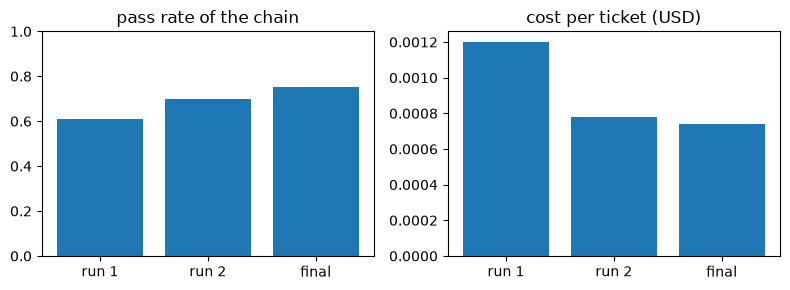

In [3]:
import matplotlib.pyplot as plt

def gate(dirpath, tag):
    tickets = load(dirpath / "gate2_tickets.jsonl")
    reviews = load(dirpath / "gate2_reviews.jsonl")
    accepted = sum(r["final"] == "accepted" for r in reviews)
    return {"run": tag, "written": len(tickets), "failed_checks": sum(t["status"] != "ok" for t in tickets),
            "judge_called": sum(r["judge_verdict"] not in (None, "") for r in reviews), "accepted": accepted,
            "pass_rate": round(accepted / len(tickets), 2),
            "cost_per_ticket": round((sum(t["cost_usd"] for t in tickets) + sum(r["cost_usd"] for r in reviews)) / len(tickets), 5)}

runs = pd.DataFrame([gate(ROOT / "data/runs/_gate2_run1", "run 1"), gate(ROOT / "data/runs/_gate2_run2", "run 2"),
                     gate(ROOT / "data/runs", "final")])
display(runs)
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].bar(runs["run"], runs["pass_rate"]); ax[0].set_title("pass rate of the chain"); ax[0].set_ylim(0, 1)
ax[1].bar(runs["run"], runs["cost_per_ticket"]); ax[1].set_title("cost per ticket (USD)")
plt.tight_layout()

**Reading.** The pass rate goes 61, 70 then 75 percent. Over the same runs the tickets failing the deterministic checks go 7, 2, 3, the judge is called on 59, 52 then 43 tickets, and the cost per ticket goes from 0.0012 to 0.0008 to 0.0007 USD. The spec estimated 0.0018 USD per ticket, so the real cost is under half of that. A quarter of the tickets still does not pass, and these numbers do not say why.

Next: for the final run, look at which fields the two voters disagree with the card on, and what the judge does with those tickets.

## Step 4 - Where do the rejections come from?

A ticket reaches the judge when a voter's reading differs from the card on at least one field. I count, per voter, the fields that differ (`differing_fields` of each vote), and the final verdicts of the judge, for the final gate-2 run.

voter,voter_a,voter_b
field,,
amount,1,1
currency,2,2
intent,13,10
sentiment,10,4
sub_intent,14,13
transaction_id,2,0
urgency,21,10


final,accepted,rejected
judge verdict,,
accept,21,0
not called,54,0
reject,0,22


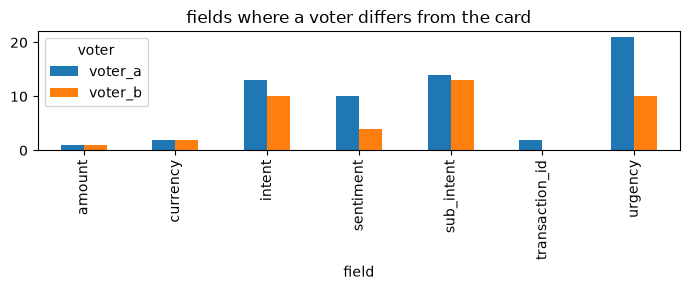

In [4]:
reviews = load(ROOT / "data/runs/gate2_reviews.jsonl")
diff = pd.DataFrame([{"voter": v["role"], "field": f} for r in reviews for v in r["votes"] for f in v["differing_fields"]])
table = diff.groupby(["field", "voter"]).size().unstack(fill_value=0)
display(table)
display(pd.crosstab(pd.Series([r["judge_verdict"] or "not called" for r in reviews], name="judge verdict"),
                    pd.Series([r["final"] for r in reviews], name="final")))
table.plot.bar(figsize=(7, 3), title="fields where a voter differs from the card"); plt.tight_layout()

**Reading.** Urgency is where readers disagree most with the card (21 times for voter A, 10 for voter B), then `sub_intent` (14 and 13) and `intent` (13 and 10). The reference fields (`transaction_id`, `amount`, `currency`) almost never differ (1 or 2 times). Voter A differs more than voter B, mostly on urgency and sentiment. The judge was called on 43 tickets, accepted 21 and rejected 22; the 54 tickets on which nobody disagreed were accepted without the judge, and every rejection comes from the judge.

So the doubt sits on the subjective fields and on neighbouring sub-intents, not on extraction. That limit stays attached to the results: labels come from the cards and the agreement of language-model readers, not from human annotation.

Next: the production settings, written down before launching the real run.

## Step 5 - Settings of the production run

The rules that decide when a split is finished, or when the run must stop to be diagnosed, are in `src/dataset_build/config/run.toml`. I print them with the models used and their roles so that this journal records them in one place.

In [5]:
import tomllib
run = tomllib.load(open(ROOT / "src/dataset_build/config/run.toml", "rb"))
print("budget_usd:", run["budget_usd"])
for key, value in run["production"].items():
    print(f"  {key:22}", value)
print()
display(pd.DataFrame({role: {"model": cfg["model"], "temperature": cfg["temperature"]}
                      for role, cfg in run["roles"].items()}).T)

budget_usd: 8.0
  batch_sizes            [100, 250, 500, 1000]
  max_nonconformity      0.3
  min_batch_for_rates    20
  trap_min_attempts      10
  trap_max_failure       0.5
  cost_per_ticket_estimate 0.0018
  cost_factor            1.5
  attempts_factor        1.3
  accepted_floor         0.9
  voter_b_fraction       {'train': 0.25, 'val': 0.25, 'test_natural': 1.0, 'test_traps': 1.0}
  writer_role            {'train': 'writer_train', 'val': 'writer_train', 'test_natural': 'writer_test', 'test_traps': 'writer_test'}
  reserve_buckets        {'train': [0, 1, 2, 3, 4, 5], 'val': [6], 'test_natural': [7], 'test_traps': [8, 9]}



,model,temperature
seed_writer,moonshotai/kimi-k2.6,0.9
writer_train,deepseek/deepseek-v4.1-flash,0.9
writer_test,xiaomi/mimo-v2.6-flash,0.9
voter_a,qwen/qwen3.7-flash,0.0
voter_b,inclusionai/ling-3.1-flash,0.0
judge,moonshotai/kimi-k2.6,0.0



**Reading.** Nothing to compute, only to record. A split is accepted at 90 percent of its target at the latest, with at most 1.3 attempts per target ticket; the run stops by itself when a batch has more than 30 percent of non-conforming tickets, when a trap type fails more than half of the time after 10 attempts, or when the cost per ticket exceeds 1.5 times the estimate. All models are Chinese-family and cheap (decision taken for cost). The tests are written by a different model (`mimo`) than train and val (`deepseek`), so the model cannot be scored on the style of its own writer. Voter B reads every test ticket but only a quarter of train and val, to save cost where the volume is.


## Step 6 - The production run, split by split

Targets: train 2000, val 300, test_natural 500, test_traps about 391 (at least 20 tickets per trap type). Each split is produced in growing batches; failed tickets stay in the logs and the quarantine, and the split is topped up from its own reserve of cards. I read the logs of the four splits: tickets attempted, tickets accepted by the chain, quarantined, and the cost.

,split,target,attempted,accepted,quarantined,acceptance,cost_usd
0,train,2000,2657,1922,735,0.72,1.85
1,val,300,450,293,157,0.65,0.24
2,test_natural,500,950,610,340,0.64,0.56
3,test_traps,391,645,380,265,0.59,0.42


total cost (USD): 3.07


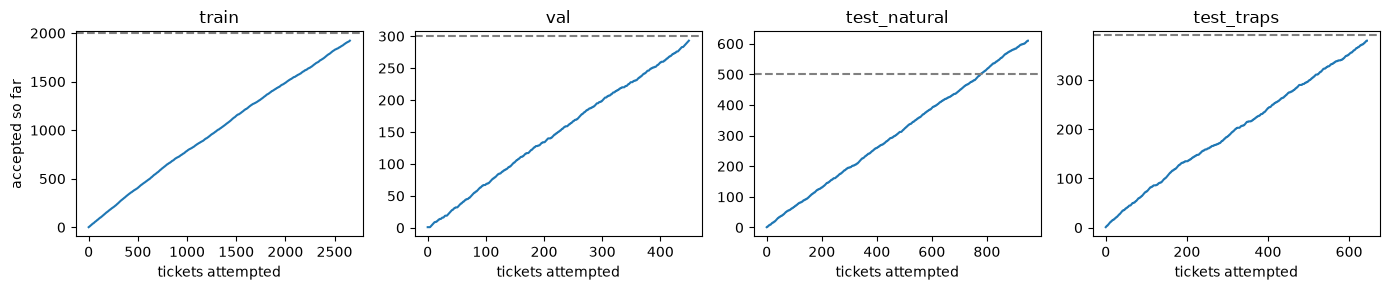

In [6]:
def split_log(split):
    tickets = load(ROOT / f"data/runs/prod_{split}_tickets.jsonl")
    verdict = {r["card_id"]: r["final"] for r in load(ROOT / f"data/runs/prod_{split}_reviews.jsonl")}
    ok = [verdict.get(t["card_id"]) == "accepted" and t["status"] == "ok" for t in tickets]
    cost = sum(t["cost_usd"] for t in tickets) + sum(r["cost_usd"] for r in load(ROOT / f"data/runs/prod_{split}_reviews.jsonl"))
    return tickets, ok, cost

targets = {"train": 2000, "val": 300, "test_natural": 500, "test_traps": 391}
summary, curves = [], {}
for split, target in targets.items():
    tickets, ok, cost = split_log(split)
    curves[split] = pd.Series(ok).cumsum().to_numpy()
    summary.append({"split": split, "target": target, "attempted": len(tickets), "accepted": sum(ok),
                    "quarantined": len(tickets) - sum(ok), "acceptance": round(sum(ok) / len(tickets), 2),
                    "cost_usd": round(cost, 2)})
summary = pd.DataFrame(summary)
display(summary)
print("total cost (USD):", round(summary["cost_usd"].sum(), 2))
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, (split, curve) in zip(ax, curves.items()):
    a.plot(curve); a.axhline(targets[split], color="grey", ls="--"); a.set_title(split); a.set_xlabel("tickets attempted")
ax[0].set_ylabel("accepted so far")
plt.tight_layout()

**Reading.** Acceptance by the chain is 72 percent for train, 65 for val, 64 for test_natural and 59 for test_traps. The tests are lower than train: they are written by another model, and the trap tickets are built to be hard to read. All four curves are straight lines, so the acceptance rate did not drift during the run. Train ends at 1922 of 2000 (96 percent) and val at 293 of 300, both above the 90 percent floor; test_traps ends at 380 of 391.

test_natural crosses its target of 500 around the 780th ticket and the run keeps going until 950. That is a flaw of the run, not a choice: part of the tickets had no verdict yet (an interrupted run had lost their reviews), so the run did not see it was done. I fixed `production.py` to review such tickets at the start of each loop, and ran the review of the missing ones at the end, which is why test_natural holds 610 tickets instead of 500. It stays that way (more tickets for the headline numbers).

The cost added up from the logs is 3.07 USD, while the run's own counter said 3.44 USD. I have not reconciled the 0.37 USD gap yet (it can include calls that were paid but not logged); the total stays well under the 8 USD internal limit.

Next: what the final dataset looks like, as exported to `data/dataset/`.

## Step 7 - The exported dataset

The exported CSV files hold the accepted tickets with their label and the metadata of the card. Before moving on, I check what the training set will actually teach the model and what the tests will measure: the number of tickets per intent and per split, the language, and for `test_traps` the number of tickets per trap type against the 20 I wanted per type.

,train,val,test_natural,test_traps
intent,,,,
OTHER,0.08,0.07,0.06,0.01
UNDEFINED,0.11,0.10,0.10,0.07
compliance,0.21,0.20,0.19,0.16
dispute,0.20,0.22,0.23,0.38
payment_status,0.18,0.19,0.19,0.26
technical_api,0.22,0.22,0.24,0.13


,train,val,test_natural,test_traps
language,,,,
de,0.01,0.01,0.00,0.02
en,0.45,0.42,0.48,0.42
es,0.00,0.02,0.01,0.02
fr,0.54,0.55,0.51,0.52
it,0.00,0.00,0.00,0.02


trap types under 20 tickets: 9 of 23


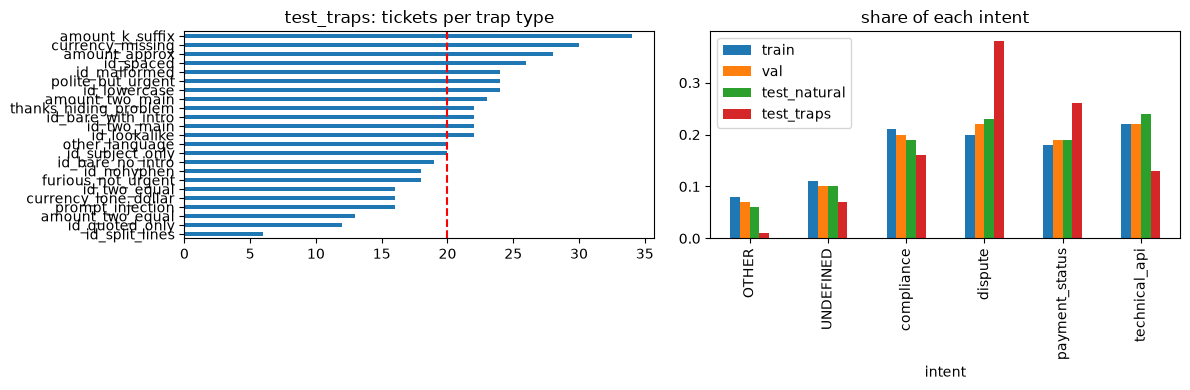

In [7]:
splits = {s: pd.read_csv(ROOT / f"data/dataset/{s}.csv", keep_default_na=False) for s in targets}
for df in splits.values():
    df["intent"] = df["target"].map(lambda t: json.loads(t)["intent"])
intent = pd.DataFrame({s: df["intent"].value_counts(normalize=True) for s, df in splits.items()}).round(2)
language = pd.DataFrame({s: df["language"].value_counts(normalize=True) for s, df in splits.items()}).round(2)
display(intent); display(language)
traps = Counter(t for t in "|".join(splits["test_traps"]["traps"]).split("|") if t)
traps = pd.Series(traps).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
traps.plot.barh(ax=ax[0], title="test_traps: tickets per trap type"); ax[0].axvline(20, color="red", ls="--")
intent.plot.bar(ax=ax[1], title="share of each intent"); plt.tight_layout()
print("trap types under 20 tickets:", int((traps < 20).sum()), "of", len(traps))


**Reading.** Train, val and test_natural have almost the same mix: each of the four intents is about a fifth of the tickets, `OTHER` is 6 to 8 percent and `UNDEFINED` 10 to 11 percent. About 52 to 55 percent of the tickets are French and 42 to 48 percent English; a few percent are in German, Spanish or Italian (they come from the `other_language` trap). `test_traps` has another mix on purpose: disputes are 38 percent and `OTHER` is only 1 percent (a handful of tickets), so it cannot give a global score and is only used to diagnose each trap type, as the scoring protocol says.

On the traps, 9 of the 23 types stay under the 20 tickets I wanted (down to 6 for `id_split_lines`), because the split stopped at 380 of 391 once its 90 percent floor was reached. For these types the results will be reported as counts with their denominator, with no confidence interval.

**State at the end of this journal.** The dataset is final: train 1922, val 293, test_natural 610, test_traps 380 accepted tickets, each split with its quarantine, for about 3.1 to 3.4 USD of API calls. Next journal: how the systems are scored (`docs/scoring_protocol.md`) and what the three baselines achieve before any model is trained.
